In [ ]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
# 1. Cargar el conjunto de datos
nombre_archivo = Path('Demandarealnacionala1c5ac9a-6d89-4612-acf8-7c59ba206713(1).csv')
df = pd.read_csv(nombre_archivo)

# Mostrar las primeras filas para identificar las columnas (opcional)
print(df.head())

  CodigoVariable            FechaHora CodigoSICAgente  TipoMercado Version  \
0        DdaReal  2026-07-22 23:00:00            EPMC  No Regulado     TXF   
1        DdaReal  2026-07-22 22:00:00            EPMC  No Regulado     TXF   
2        DdaReal  2026-07-22 21:00:00            EPMC  No Regulado     TXF   
3        DdaReal  2026-07-22 20:00:00            EPMC  No Regulado     TXF   
4        DdaReal  2026-07-22 19:00:00            EPMC  No Regulado     TXF   

       Valor UnidadMedida CodigoDuracion  
0  596742.10          kWh           PT1H  
1  607580.37          kWh           PT1H  
2  611331.57          kWh           PT1H  
3  630106.88          kWh           PT1H  
4  652245.02          kWh           PT1H  


In [ ]:
# 2. Preparar la serie de tiempo
import numpy as np

columna_fecha = 'FechaHora'
columna_demanda = 'Valor'

# Convertir la columna de fecha a datetime
df[columna_fecha] = pd.to_datetime(df[columna_fecha])

# 1er paso: Agrupar por hora exacta y sumar para agregar a todos los agentes
df_agrupado_hora = df.groupby(columna_fecha)[columna_demanda].sum()

# 2do paso: Remuestrear cronológicamente a frecuencia diaria ('D') y calcular el promedio
df_diario = df_agrupado_hora.resample('D').mean()

# Extraer la serie usando la escala original (sin aplicar logaritmo natural)
serie_tiempo_completa = df_diario

# Recortar la muestra a los últimos 6 meses de observaciones
fecha_fin = serie_tiempo_completa.index.max()
fecha_inicio = fecha_fin - pd.DateOffset(months=6)
serie_tiempo = serie_tiempo_completa.loc[fecha_inicio:fecha_fin]

print(serie_tiempo.head())
print(f'\nCantidad de días en la muestra de los últimos 6 meses (escala original): {len(serie_tiempo)}')
print(f'Rango de fechas: desde {serie_tiempo.index.min().strftime("%Y-%m-%d")} hasta {serie_tiempo.index.max().strftime("%Y-%m-%d")}')

FechaHora
2026-03-30    3.065501e+06
2026-03-31    3.063189e+06
2026-04-01    2.863730e+06
2026-04-02    2.551360e+06
2026-04-03    2.416937e+06
Freq: D, Name: Valor, dtype: float64

Cantidad de días en la muestra de los últimos 6 meses (escala original): 185
Rango de fechas: desde 2026-03-30 hasta 2026-09-30


In [ ]:
# 3. Definir y estimar el modelo SARIMA(2,0,0)(2,1,0,168)
# order = (p, d, q) -> (2, 0, 3)
# seasonal_order = (P, D, Q, s) -> (1, 1, 3, 7)
modelo_sarima = sm.tsa.statespace.SARIMAX(
    serie_tiempo,
    order=(2, 0, 3),
    seasonal_order=(1, 1, 3, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Ajustar el modelo usando Máxima Verosimilitud (MLE)
# 'lbfgs' es el optimizador por defecto que maximiza la función de verosimilitud logarítmica
resultados = modelo_sarima.fit(method='lbfgs', disp=False)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
# 4. Mostrar el resumen estadístico
print(resultados.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             Valor   No. Observations:                  185
Model:             SARIMAX(2, 0, 3)x(1, 1, 3, 7)   Log Likelihood               -1977.133
Date:                           Sat, 24 Oct 2026   AIC                           3974.265
Time:                                   03:39:25   BIC                           4004.570
Sample:                               03-30-2026   HQIC                          3986.575
                                    - 09-30-2026                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3455      0.206      6.518      0.000       0.941       1.750
ar.L2         -0.3787      0.224     -1.689

In [ ]:
# 5. Verificación de supuestos sobre los residuos
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

# --- 0. Descartar el periodo de inicialización difusa (igual que summary y plot_diagnostics)
burn = int(max(resultados.loglikelihood_burn, resultados.nobs_diffuse))
z = pd.Series(resultados.standardized_forecasts_error[0, burn:],
              index=resultados.resid.index[burn:])        # residuos estandarizados
print(f"burn = {burn} | n usado = {len(z)}")

# --- 1. Ljung-Box
# L1 sin ajuste de gl, para replicar el resumen (debería dar Q ≈ 0.01, p ≈ 0.93)
print(acorr_ljungbox(z, lags=[1], return_df=True))

# Rezagos estacionales, ajustando gl por los parámetros ARMA estimados: p + q + P + Q = 2 + 1 + 1 + 0
model_df = 2 + 1 + 1 + 0
print(acorr_ljungbox(z, lags=[7, 14, 21, 28], model_df=model_df, return_df=True))

# --- 2. Jarque-Bera (debería dar ≈ 138.47, skew ≈ -0.11, kurtosis ≈ 7.43)
jb, jb_p, skew, kurt = jarque_bera(z)
print(f"JB = {jb:.2f}, p = {jb_p:.4f}, skew = {skew:.2f}, kurtosis = {kurt:.2f}")

# --- 3. ARCH-LM
lm, lm_p, f, f_p = het_arch(z, nlags=7)
print(f"LM = {lm:.2f}, p = {lm_p:.4f}")

burn = 32 | n usado = 153
    lb_stat  lb_pvalue
1  1.656411   0.198089
      lb_stat  lb_pvalue
7    5.571804   0.134406
14  11.806261   0.298232
21  25.012148   0.094438
28  33.015503   0.103747
JB = 34.72, p = 0.0000, skew = -0.18, kurtosis = 5.30
LM = 25.15, p = 0.0007


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


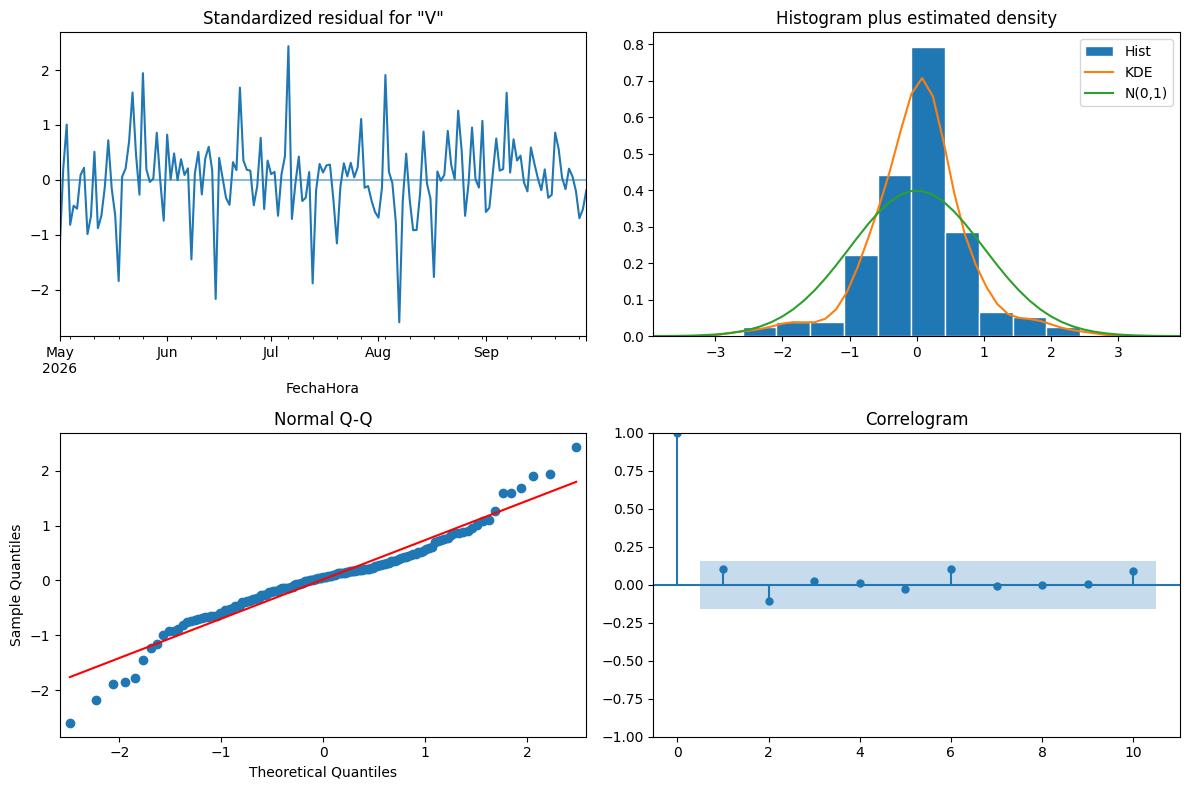

In [ ]:
# 5. (Opcional) Diagnóstico del modelo para ver los residuos
resultados.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

--- Pronósticos para los próximos 10 periodos ---
2026-10-01    3.131536e+06
2026-10-02    3.172015e+06
2026-10-03    2.926634e+06
2026-10-04    2.569067e+06
2026-10-05    3.024359e+06
2026-10-06    3.106909e+06
2026-10-07    3.136227e+06
2026-10-08    3.144663e+06
2026-10-09    3.186382e+06
2026-10-10    2.924724e+06
Freq: D, Name: predicted_mean, dtype: float64


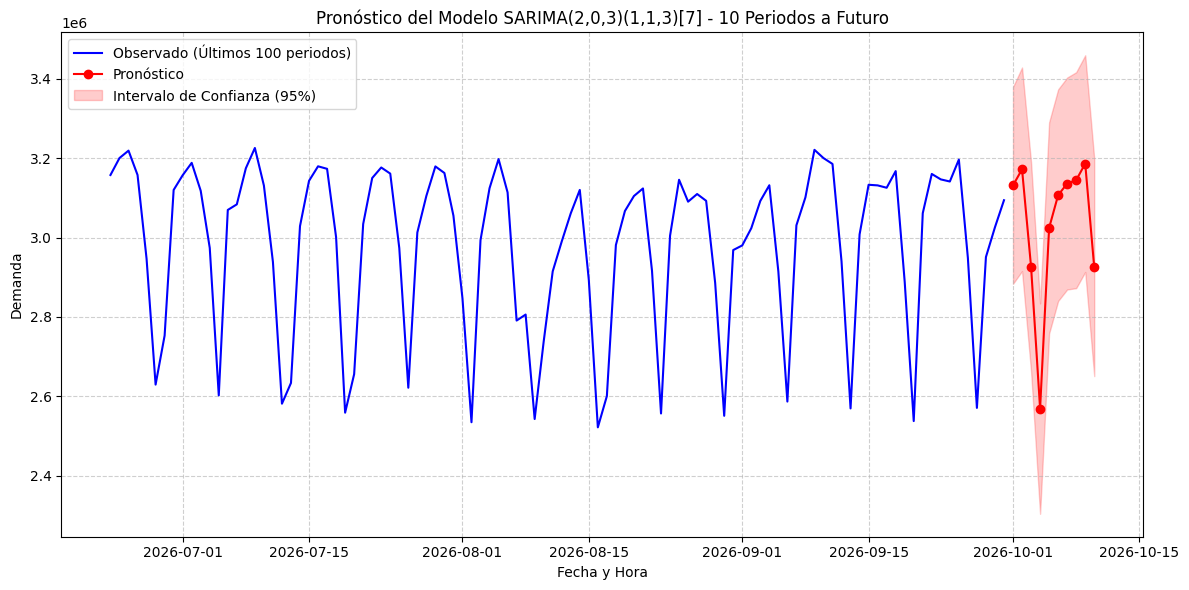

In [ ]:
# 6. Pronósticos para 10 periodos en el futuro

pasos_futuros = 10
pronostico = resultados.get_forecast(steps=pasos_futuros)

# Extraer la media pronosticada y los intervalos de confianza
media_pronosticada = pronostico.predicted_mean
intervalos_confianza = pronostico.conf_int()

print("--- Pronósticos para los próximos 10 periodos ---")
print(media_pronosticada)

# Visualizar el pronóstico junto con los últimos datos históricos
plt.figure(figsize=(12, 6))

# Graficar los últimos 100 datos observados para dar contexto
plt.plot(serie_tiempo.iloc[-100:], label='Observado (Últimos 100 periodos)', color='blue')

# Graficar la media del pronóstico
plt.plot(media_pronosticada.index, media_pronosticada, label='Pronóstico', color='red', marker='o')

# Sombrear el intervalo de confianza del 95%
plt.fill_between(
    intervalos_confianza.index,
    intervalos_confianza.iloc[:, 0],
    intervalos_confianza.iloc[:, 1],
    color='red',
    alpha=0.2,
    label='Intervalo de Confianza (95%)'
)

plt.title('Pronóstico del Modelo SARIMA(2,0,3)(1,1,3)[7] - 10 Periodos a Futuro')
plt.xlabel('Fecha y Hora')
plt.ylabel('Demanda')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()